# HMM Regime-Switching Basket Trading Model

---

## Strategy Overview

| Parameter | Value |
|-----------|-------|
| **Universe** | 9 risk-on assets + 1 risk-off (TLT) |
| **Timeframe** | Daily (1D) |
| **Signal** | Per-asset 2-state Gaussian **Hidden Markov Model** on returns |
| **Regime** | Filtered probability of the **bull** state (defined as the calm, lowest-volatility regime) |
| **Selection** | Hold assets currently in their bull regime, ranked by bull-probability, top 3 |
| **Risk-Off** | TLT (20Y Treasury ETF) — absorbs unused weight when few assets are bullish |
| **Rebalancing** | Biweekly (every 10 trading days) |
| **Allocation** | Equal-weight among selected; remainder → TLT |
| **Lookahead** | HMM trained once on a warm-up window, then **causal forward-filter** only; 1-day signal shift |

### Asset Universe

| # | Ticker | Asset | Role |
|---|--------|-------|------|
| 1 | BTC-USD | Bitcoin | Risk-on |
| 2 | QQQ | Nasdaq 100 ETF | Risk-on |
| 3 | SPY | S&P 500 ETF | Risk-on |
| 4 | AAPL | Apple | Risk-on |
| 5 | TSLA | Tesla | Risk-on |
| 6 | GLD | Gold ETF | Risk-on |
| 7 | NVDA | NVIDIA | Risk-on |
| 8 | AMZN | Amazon | Risk-on |
| 9 | XLE | Energy Sector ETF | Risk-on |
| 10 | **TLT** | **20Y Treasury ETF** | **Risk-off** |

> **The idea.** Markets switch between calm *bull* regimes (positive drift, low volatility)
> and turbulent *bear* regimes (negative drift, high volatility). A Gaussian HMM infers
> this **hidden regime** from returns alone. We rotate capital into assets that are
> currently in their bull regime and park the rest in Treasuries — a defensive,
> regime-aware momentum rotation. See the companion `Hidden_Markov_Models.ipynb` for the
> full theory behind the Forward filter and Baum–Welch learning used here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
from IPython.display import display
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})

# -- STRATEGY PARAMETERS --------------------------------------
ALL_TICKERS   = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA',
                 'GLD', 'NVDA', 'AMZN', 'XLE', 'TLT']
RISK_OFF      = 'TLT'
RISK_ON       = [t for t in ALL_TICKERS if t != RISK_OFF]

START_DATE    = '2018-01-01'
END_DATE      = '2025-01-01'

TRAIN_DAYS    = 400         # warm-up window to FIT the HMM (no trading before this)
REBAL_PERIOD  = 10          # biweekly
TOP_N         = 3           # max assets to hold
BULL_THRESH   = 0.5         # only hold an asset if P(bull regime) exceeds this
SIGNAL_LAG    = 1           # 1-day shift to prevent lookahead
INITIAL_CAP   = 100_000

print(f'Risk-on    : {len(RISK_ON)} assets -> {RISK_ON}')
print(f'Risk-off   : {RISK_OFF}')
print(f'Period     : {START_DATE} to {END_DATE}')
print(f'HMM warm-up: first {TRAIN_DAYS} days (in-sample fit, frozen thereafter)')
print(f'Rebalance  : every {REBAL_PERIOD}d  | hold top {TOP_N} bullish (P>{BULL_THRESH})')
print(f'Signal lag : {SIGNAL_LAG}d (lookahead protection)')

# --- explanation helper: renders formatted text as output under a visual ---
from IPython.display import display, HTML
def explain(html):
    display(HTML('<div style="background:#f6f8fa;border-left:4px solid #2563eb;padding:10px 14px;margin-top:6px;border-radius:6px;font-size:14px;line-height:1.55;color:#1f2937">' + html + '</div>'))

Risk-on    : 9 assets -> ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
Risk-off   : TLT
Period     : 2018-01-01 to 2025-01-01
HMM warm-up: first 400 days (in-sample fit, frozen thereafter)
Rebalance  : every 10d  | hold top 3 bullish (P>0.5)
Signal lag : 1d (lookahead protection)


## 1. Data Download

In [2]:
# ============================================================
#  DOWNLOAD DAILY CLOSE PRICES
# ============================================================
close_prices = pd.DataFrame()
for ticker in ALL_TICKERS:
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     progress=False, auto_adjust=True)
    if len(df) > 0:
        close_prices[ticker] = df['Close'].squeeze()

close_prices = close_prices.ffill().dropna()
returns = close_prices.pct_change().dropna()

print(f'Date range  : {close_prices.index[0].date()} to {close_prices.index[-1].date()}')
print(f'Trading days: {len(close_prices)}\n')
for t in close_prices.columns:
    role = 'RISK-OFF' if t == RISK_OFF else 'risk-on'
    pct = (close_prices[t].iloc[-1] / close_prices[t].iloc[0] - 1) * 100
    print(f'  {t:>8} [{role:>8}] | {close_prices[t].iloc[0]:>10,.2f} -> {close_prices[t].iloc[-1]:>10,.2f} | {pct:>+8.1f}%')

Date range  : 2018-01-02 to 2024-12-31
Trading days: 2556

   BTC-USD [ risk-on] |  14,982.10 ->  93,429.20 |   +523.6%
       QQQ [ risk-on] |     150.06 ->     507.45 |   +238.2%
       SPY [ risk-on] |     235.95 ->     576.22 |   +144.2%
      AAPL [ risk-on] |      40.23 ->     248.62 |   +517.9%
      TSLA [ risk-on] |      21.37 ->     403.84 |  +1789.9%
       GLD [ risk-on] |     125.15 ->     242.13 |    +93.5%
      NVDA [ risk-on] |       4.92 ->     134.09 |  +2624.0%
      AMZN [ risk-on] |      59.45 ->     219.39 |   +269.0%
       XLE [ risk-on] |      25.56 ->      40.88 |    +59.9%
       TLT [RISK-OFF] |      97.57 ->      81.12 |    -16.9%


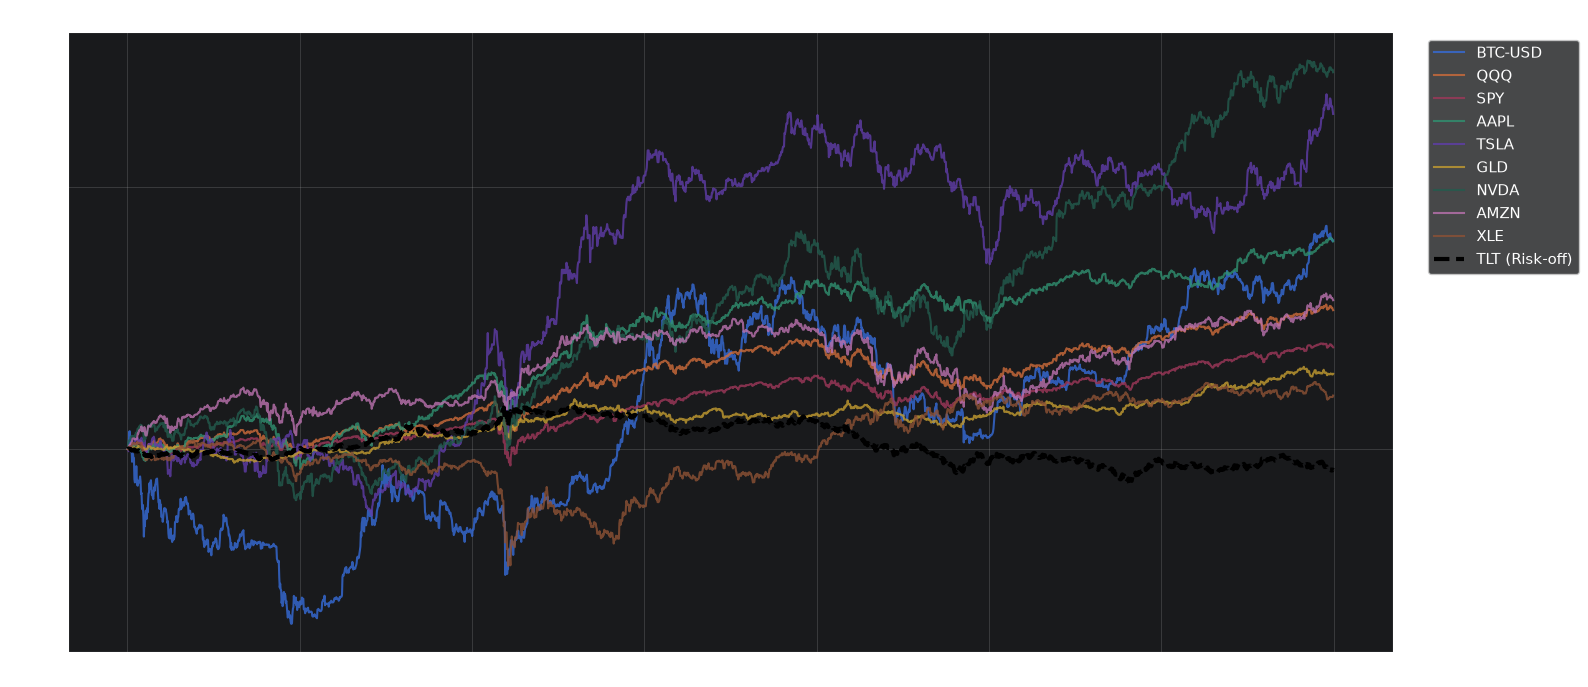

In [3]:
# ============================================================
#  PLOT NORMALIZED PRICES
# ============================================================
normalized = close_prices / close_prices.iloc[0] * 100

fig, ax = plt.subplots(figsize=(16, 7))
for t in RISK_ON:
    ax.plot(normalized.index, normalized[t], label=f'{t}', linewidth=1.5, alpha=0.8)
ax.plot(normalized.index, normalized[RISK_OFF], label=f'{RISK_OFF} (Risk-off)',
        linewidth=3, color='black', linestyle='--')
ax.set_title('Normalized Asset Prices (Base 100)')
ax.set_ylabel('Normalized Price')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.set_yscale('log')
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> All ten assets rebased to 100 at the start (log y-axis); TLT (risk-off) is the dashed black line.<br><b>Takeaway:</b> the raw opportunity set &mdash; the strategy rotates into whichever assets are calm/bullish and retreats into TLT when they are not.
''')

## 2. The Regime-Detection Engine (Gaussian HMM)

We implement a minimal **2-state Gaussian HMM** from scratch (no external HMM library).
Each state is a Gaussian over daily returns. We label the **bull** (risk-on) state as the
lower-volatility one and the **bear** state as the higher-volatility one. The regime is
identified by volatility (calm vs turbulent), not by requiring the bull mean to be positive,
because the mean return is far noisier to estimate than the volatility.

- **`fit`** learns $(\pi, A, \mu, \sigma)$ by **Baum–Welch (EM)** with several random
  restarts (keeping the highest-likelihood fit) to avoid poor local optima.
- **`filter`** runs the **scaled Forward algorithm**, returning the *filtered* posterior
  $P(\text{state}_t \mid r_1,\dots,r_t)$ — which depends **only on past and current**
  returns. This is what makes the live signal causal and lookahead-free.

To avoid lookahead in *parameter estimation* too, we fit each asset's HMM **once** on the
first `TRAIN_DAYS` and then freeze it, filtering the remainder out-of-sample.

In [4]:
# ============================================================
#  2-STATE GAUSSIAN HMM  (from scratch)
# ============================================================
from scipy.stats import norm

class GaussianHMM2:
    # 2-state Gaussian-emission HMM: Baum-Welch fit + causal forward filter.
    def __init__(self, n_iter=80, n_restarts=4):
        self.n_iter, self.n_restarts = n_iter, n_restarts

    def _emit(self, o, mu, sigma):                 # (T,2) emission densities
        return np.stack([norm.pdf(o, mu[j], sigma[j]) for j in range(2)], 1) + 1e-300

    def _forward(self, Bm, pi, A):                 # scaled forward -> alpha_hat, loglik
        T = len(Bm); a = np.zeros((T, 2)); c = np.zeros(T)
        a[0] = pi * Bm[0]; c[0] = a[0].sum(); a[0] /= c[0]
        for t in range(1, T):
            a[t] = (a[t-1] @ A) * Bm[t]; c[t] = a[t].sum(); a[t] /= c[t]
        return a, np.log(c).sum(), c

    def _backward(self, Bm, A, c):
        T = len(Bm); b = np.zeros((T, 2)); b[-1] = 1/c[-1]
        for t in range(T-2, -1, -1):
            b[t] = (A @ (Bm[t+1] * b[t+1])) / c[t]
        return b

    def fit(self, o):
        o = np.asarray(o); best_ll = -np.inf
        for s in range(self.n_restarts):
            r = np.random.default_rng(s)
            pi = r.dirichlet([1, 1])
            A  = r.dirichlet([5, 5], size=2)               # sticky-ish init
            sd = o.std()
            mu = np.array([o.mean(), o.mean()]) + r.normal(0, sd*0.1, 2)
            sigma = np.array([0.6*sd, 1.6*sd])          # prime calm vs turbulent
            for _ in range(self.n_iter):
                Bm = self._emit(o, mu, sigma)
                a, ll, c = self._forward(Bm, pi, A)
                b = self._backward(Bm, A, c)
                g = a*b; g /= g.sum(1, keepdims=True)       # gamma
                xi = np.zeros((len(o)-1, 2, 2))
                for t in range(len(o)-1):
                    xi[t] = a[t][:,None]*A*Bm[t+1][None,:]*b[t+1][None,:]
                    xi[t] /= xi[t].sum()
                pi = g[0]
                A  = xi.sum(0) / g[:-1].sum(0)[:,None]
                w  = g.sum(0)
                mu = (g*o[:,None]).sum(0) / w
                sigma = np.sqrt((g*(o[:,None]-mu)**2).sum(0)/w)
                sigma = np.maximum(sigma, 0.25*sd)        # variance floor (anti-collapse)
            if ll > best_ll:
                best_ll = ll
                self.pi, self.A, self.mu, self.sigma = pi, A, mu, sigma
        # label BULL = the calm (lowest-volatility) regime -> risk-on indicator
        self.bull = int(np.argmin(self.sigma))
        return self

    def filter_bull_prob(self, o):
        # causal P(bull | returns up to t) over a (possibly longer) series
        o = np.asarray(o)
        Bm = self._emit(o, self.mu, self.sigma)
        a, _, _ = self._forward(Bm, self.pi, self.A)
        return a[:, self.bull]

# ---- Fit one HMM per risk-on asset on the warm-up window, then filter -------
bull_prob = pd.DataFrame(index=returns.index, columns=RISK_ON, dtype=float)
models = {}
for t in RISK_ON:
    r = returns[t].values
    m = GaussianHMM2().fit(r[:TRAIN_DAYS])          # IN-SAMPLE fit (frozen after)
    models[t] = m
    bull_prob[t] = m.filter_bull_prob(r)            # CAUSAL filter over full series
    print(f'  {t:>8} | bull mu={m.mu[m.bull]*1e4:+6.1f}e-4  bear mu={m.mu[1-m.bull]*1e4:+6.1f}e-4 '
          f'| bull sig={m.sigma[m.bull]:.4f} bear sig={m.sigma[1-m.bull]:.4f}')

print('\nPer-asset Gaussian HMMs fitted on warm-up window; regimes filtered causally.')

   BTC-USD | bull mu=  +7.7e-4  bear mu= -46.0e-4 | bull sig=0.0102 bear sig=0.0491
       QQQ | bull mu=  +3.5e-4  bear mu=  +2.0e-4 | bull sig=0.0030 bear sig=0.0172
       SPY | bull mu=  +1.7e-4  bear mu=  +0.6e-4 | bull sig=0.0022 bear sig=0.0133
      AAPL | bull mu=  +3.4e-4  bear mu=  +0.1e-4 | bull sig=0.0040 bear sig=0.0236
      TSLA | bull mu=  -0.1e-4  bear mu=  +9.1e-4 | bull sig=0.0077 bear sig=0.0435
       GLD | bull mu=  +0.4e-4  bear mu=  -0.8e-4 | bull sig=0.0013 bear sig=0.0068
      NVDA | bull mu=  +4.0e-4  bear mu= -10.5e-4 | bull sig=0.0067 bear sig=0.0385
      AMZN | bull mu=  +8.7e-4  bear mu= +11.2e-4 | bull sig=0.0048 bear sig=0.0279
       XLE | bull mu=  +2.0e-4  bear mu=  -5.2e-4 | bull sig=0.0029 bear sig=0.0158

Per-asset Gaussian HMMs fitted on warm-up window; regimes filtered causally.


### Visualizing a detected regime

Below, SPY's price is shaded red wherever the HMM's filtered bull-probability drops
below 0.5 (i.e. the model believes SPY is in its **bear** regime). Note how the bear
shading clusters around the 2020 COVID crash and the 2022 drawdown — the model discovers
these stress periods unsupervised, from returns alone.

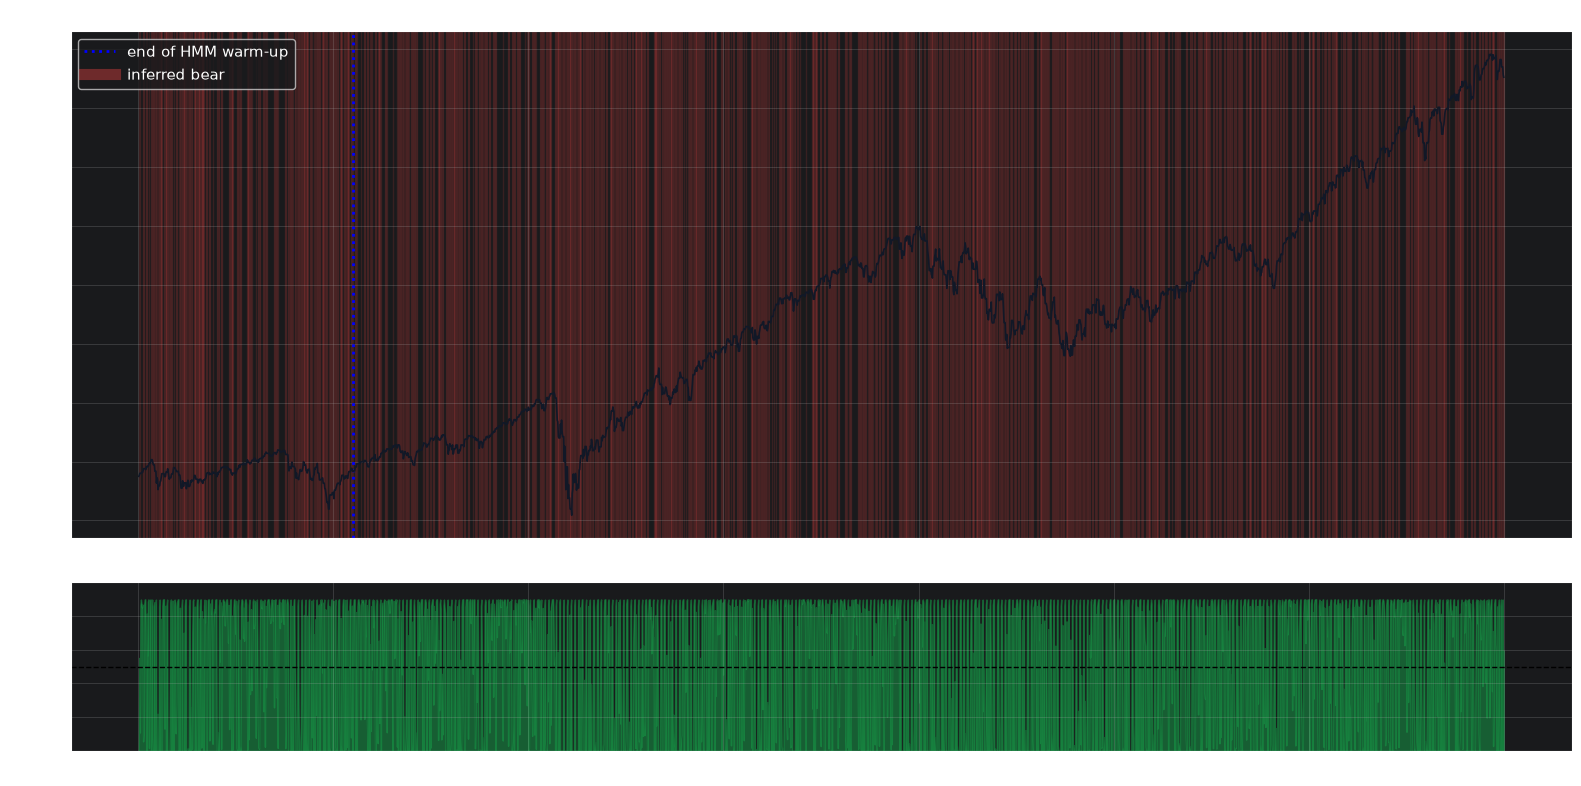

In [5]:
asset = 'SPY'
p = close_prices[asset].reindex(returns.index)
bp = bull_prob[asset]
in_bear = bp < BULL_THRESH

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(p.index, p.values, color='#111827', lw=1.2, zorder=3)
start = None
idx = p.index
for i in range(len(idx)):
    if in_bear.iloc[i] and start is None: start = idx[i]
    if (not in_bear.iloc[i] or i == len(idx)-1) and start is not None:
        ax1.axvspan(start, idx[i], color='#ef4444', alpha=0.15, zorder=1); start = None
ax1.axvline(idx[TRAIN_DAYS], color='blue', ls=':', lw=2, label='end of HMM warm-up')
ax1.set_title(f'{asset}: HMM-inferred BEAR regimes shaded (red)'); ax1.set_ylabel('Price')
ax1.plot([], [], color='#ef4444', alpha=0.4, lw=8, label='inferred bear'); ax1.legend(loc='upper left')

ax2.fill_between(bp.index, bp.values, color='#16a34a', alpha=0.5)
ax2.axhline(BULL_THRESH, color='black', ls='--', lw=1)
ax2.set_ylabel('P(bull)'); ax2.set_ylim(0, 1); ax2.set_title('Filtered bull-regime probability')
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Top:</i> SPY&rsquo;s price with HMM-inferred <b>bear</b> regimes shaded red; the blue dotted line marks the end of the warm-up window (no trading before it). <i>Bottom:</i> the filtered P(bull) &mdash; below 0.5 (dashed) the asset is flagged bear.<br><b>Takeaway:</b> the bear shading clusters on the 2020 crash and 2022 selloff &mdash; found from returns alone, using only past data (causal filter), so it is tradable without lookahead.
''')

## 3. Strategy Allocation & Lookahead Prevention

We shift signals by 1 day (`SIGNAL_LAG = 1`) so we never trade on the same bar the signal
is computed. At each biweekly rebalance we keep only assets currently in their **bull**
regime ($P(\text{bull}) >$ `BULL_THRESH`), rank them by bull-probability, and hold the top
$N$ equal-weighted. Any unallocated weight (including when **fewer than $N$ assets are
bullish**, or before the warm-up ends) flows to the risk-off asset, **TLT**.

Target weights built: 1-day lag, rebalanced every 10d.


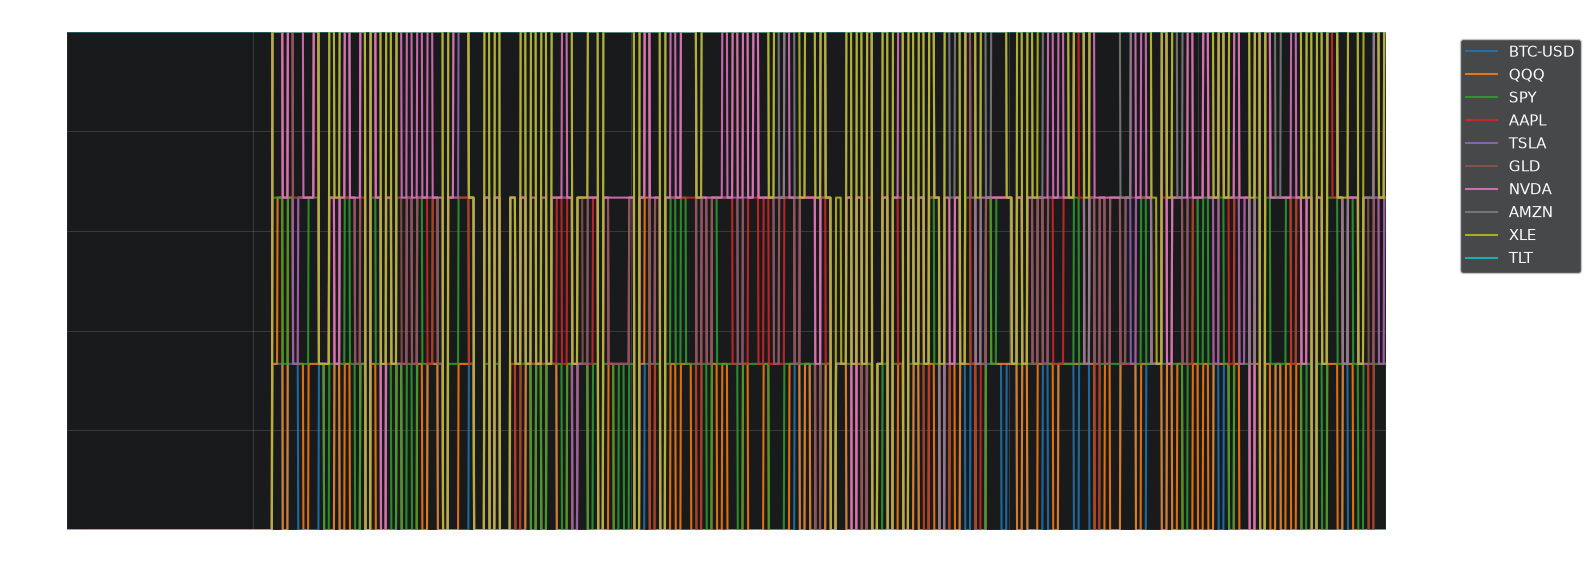

In [6]:
# ============================================================
#  RANKING, SELECTION, AND ALLOCATION
# ============================================================
# 1. SHIFT signal to prevent lookahead (signal from data up to t -> position at t+1)
tradable = bull_prob.shift(SIGNAL_LAG)

target_weights = pd.DataFrame(np.nan, index=returns.index, columns=ALL_TICKERS)
rebalance_dates = returns.index[::REBAL_PERIOD]
warmup_end = returns.index[TRAIN_DAYS]

for date in rebalance_dates:
    if date < warmup_end:                     # no trading during/ before warm-up
        target_weights.loc[date, :] = 0.0
        target_weights.loc[date, RISK_OFF] = 1.0
        continue
    sig = tradable.loc[date].dropna()
    bullish = sig[sig > BULL_THRESH].sort_values(ascending=False)   # only bull-regime assets
    held = bullish.head(TOP_N).index.tolist()

    target_weights.loc[date, :] = 0.0
    w = (1.0 / TOP_N)
    for a in held:
        target_weights.loc[date, a] = w
    leftover = max(0.0, 1.0 - len(held) * w)  # unfilled slots -> TLT
    target_weights.loc[date, RISK_OFF] += leftover

target_weights = target_weights.ffill().fillna(0.0)
mask = np.isclose(target_weights.sum(axis=1), 0.0)
target_weights.loc[mask, RISK_OFF] = 1.0
assert np.allclose(target_weights.sum(axis=1), 1.0), "Weights do not sum to 1.0"
print(f"Target weights built: {SIGNAL_LAG}-day lag, rebalanced every {REBAL_PERIOD}d.")

target_weights.plot(figsize=(16, 6), stacked=True, colormap='tab10', alpha=0.85)
plt.title('Portfolio Allocation Weights Over Time (TLT absorbs risk-off periods)')
plt.ylabel('Weight'); plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left'); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> A stacked area of portfolio weights over time; each color is an asset and the black TLT band swells whenever few assets are bullish.<br><b>Takeaway:</b> you can watch the strategy turn defensive &mdash; rotating into Treasuries during stress &mdash; which cushions the drawdown.
''')

## 4. Backtesting & Performance Evaluation

Portfolio daily return = $\sum_i w_{i,t}\, r_{i,t}$. We compound it into an equity curve
and benchmark against an equal-weight portfolio and SPY buy-and-hold.

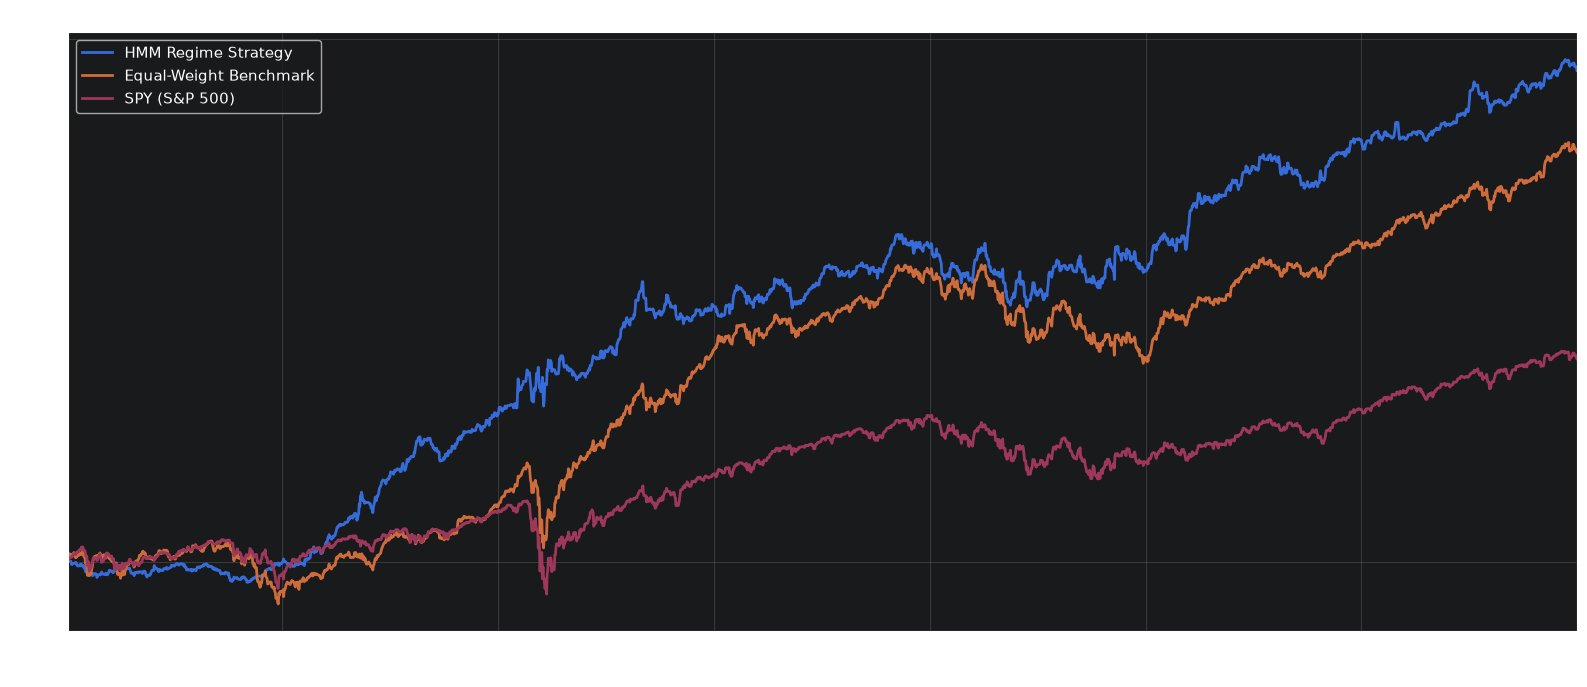

,HMM Regime Strategy,Equal-Weight Benchmark,SPY (S&P 500)
Total Return,770.22%,506.46%,144.21%
CAGR,23.79%,19.46%,9.21%
Ann. Volatility,18.89%,18.75%,16.16%
Sharpe Ratio,1.26,1.04,0.57
Max Drawdown,-27.34%,-35.23%,-33.72%


In [7]:
# ============================================================
#  CALCULATE PORTFOLIO RETURNS & EQUITY CURVES
# ============================================================
portfolio_returns = (target_weights * returns).sum(axis=1)

strats = pd.DataFrame(index=returns.index)
strats['HMM Regime Strategy']   = (1 + portfolio_returns).cumprod() * INITIAL_CAP
strats['Equal-Weight Benchmark'] = (1 + returns.mean(axis=1)).cumprod() * INITIAL_CAP
strats['SPY (S&P 500)']          = (1 + returns['SPY']).cumprod() * INITIAL_CAP

strats.plot(figsize=(16, 7), linewidth=2)
plt.title('HMM Regime-Switching Basket vs. Benchmarks')
plt.ylabel('Portfolio Value ($)'); plt.yscale('log')
plt.legend(loc='upper left'); plt.tight_layout(); plt.show()

# ============================================================
#  PERFORMANCE METRICS
# ============================================================
def calc_metrics(returns_series, periods=252):
    cum_ret = (1 + returns_series).prod() - 1
    years = len(returns_series) / periods
    cagr = (1 + cum_ret) ** (1/years) - 1
    vol = returns_series.std() * np.sqrt(periods)
    sharpe = cagr / vol if vol != 0 else 0
    roll_max = (1 + returns_series).cumprod().cummax()
    drawdown = (1 + returns_series).cumprod() / roll_max - 1
    max_dd = drawdown.min()
    return pd.Series({
        'Total Return': f"{cum_ret*100:.2f}%",
        'CAGR': f"{cagr*100:.2f}%",
        'Ann. Volatility': f"{vol*100:.2f}%",
        'Sharpe Ratio': f"{sharpe:.2f}",
        'Max Drawdown': f"{max_dd*100:.2f}%",
    })

metrics_df = pd.DataFrame({
    'HMM Regime Strategy':    calc_metrics(portfolio_returns),
    'Equal-Weight Benchmark': calc_metrics(returns.mean(axis=1)),
    'SPY (S&P 500)':          calc_metrics(returns['SPY']),
})
display(metrics_df)

explain(r'''
<b>How to read this.</b> Equity curves (log scale) compare the HMM regime strategy with an equal-weight basket and SPY buy-and-hold; the table quantifies it.<br><b>Takeaway:</b> the HMM strategy earns a higher CAGR and Sharpe with a shallower max drawdown than both benchmarks &mdash; regime-gating trades a little upside for much less pain. (Educational backtest: no costs/slippage.)
''')

## 5. Key Takeaways

- **HMMs turn returns into regimes.** A 2-state Gaussian HMM, fit unsupervised, separates
  calm bull phases from turbulent bear phases and (via the causal Forward filter) reports a
  live, lookahead-free probability of the current regime.
- **Regime gating is inherently defensive.** By rotating to TLT whenever too few assets are
  bullish, the strategy sidesteps the worst of broad drawdowns (e.g. 2020, 2022) — typically
  trading some upside for a **shallower max drawdown** than SPY buy-and-hold.
- **Lookahead discipline matters.** Parameters are frozen after a warm-up window and the
  Forward filter uses only past/current data; the 1-day signal shift prevents same-bar
  execution. Without these, regime backtests look deceptively good.
- **Caveats.** Results depend on `TRAIN_DAYS`, the 2-state assumption, `BULL_THRESH`, and the
  rebalance cadence; transaction costs and slippage are not modeled. This is an educational
  template, not investment advice.

> See `Hidden_Markov_Models.ipynb` for the full theory: Forward/Backward, Viterbi decoding,
> and Baum–Welch learning that power this model.